In [1]:
import pandas as pd
path = "https://raw.githubusercontent.com/ulka29/paper/7aad80ab3fe4ad5ffeabffb7c30bcb70edb218bd/01_data/processed/df_cleaned.csv"# import Check dataset
df= pd.read_csv(path)
df.head()

,tweet_text,cyberbullying_type,clean_tweet,lemmatized_tweet,sentiment_scores,negative,positive,neutral,compound
0,"in other words #katandandre, your food was cra...",not_cyberbullying,words katandandre food crapilicious mkr,word katandandre food crapilicious mkr,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
1,why is #aussietv so white? #mkr #theblock #ima...,not_cyberbullying,aussietv white mkr theblock imacelebrityau tod...,aussietv white mkr theblock imacelebrityau tod...,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound...",0.000,0.000,1.000,0.0000
2,@xochitlsuckkks a classy whore? or more red ve...,not_cyberbullying,classy whore red velvet cupcakes,classy whore red velvet cupcake,"{'neg': 0.32, 'neu': 0.481, 'pos': 0.199, 'com...",0.320,0.199,0.481,-0.4137
3,"@jason_gio meh. :p thanks for the heads up, b...",not_cyberbullying,meh p thanks heads concerned another angry dud...,meh p thanks head concerned another angry dude...,"{'neg': 0.243, 'neu': 0.607, 'pos': 0.15, 'com...",0.243,0.150,0.607,-0.4854
4,@rudhoeenglish this is an isis account pretend...,not_cyberbullying,isis account pretending kurdish account like i...,isi account pretending kurdish account like is...,"{'neg': 0.129, 'neu': 0.691, 'pos': 0.18, 'com...",0.129,0.180,0.691,0.0258


In [2]:
# Select relevant features for SA + ML
df_ml = df[
    [
        'lemmatized_tweet',
        'negative',
        'positive',
        'neutral',
        'compound',
        'cyberbullying_type'
    ]
].copy()

# Check shape
print("\n:-------------Shape::-------------", df_ml.shape)

# Check column names
print("\n:-------------Columns::-------------")
print(df_ml.columns.tolist())

# Check missing values
print("\n----------------Missing values:-------------")
print(df_ml.isnull().sum())

# Display first 5 rows
df_ml.head()


:-------------Shape::------------- (42645, 6)

:-------------Columns::-------------
['lemmatized_tweet', 'negative', 'positive', 'neutral', 'compound', 'cyberbullying_type']

----------------Missing values:-------------
lemmatized_tweet      30
negative               0
positive               0
neutral                0
compound               0
cyberbullying_type     0
dtype: int64


,lemmatized_tweet,negative,positive,neutral,compound,cyberbullying_type
0,word katandandre food crapilicious mkr,0.000,0.000,1.000,0.0000,not_cyberbullying
1,aussietv white mkr theblock imacelebrityau tod...,0.000,0.000,1.000,0.0000,not_cyberbullying
2,classy whore red velvet cupcake,0.320,0.199,0.481,-0.4137,not_cyberbullying
3,meh p thanks head concerned another angry dude...,0.243,0.150,0.607,-0.4854,not_cyberbullying
4,isi account pretending kurdish account like is...,0.129,0.180,0.691,0.0258,not_cyberbullying


Classes: ['age', 'ethnicity', 'gender', 'not_cyberbullying', 'other_cyberbullying', 'religion']
Dataset shape: (42645, 6)

Training samples: 29851
Testing samples : 12794

Feature matrix dimensions
-------------------------------------------------------
Word TF-IDF                  | Train: (29851, 10004) | Test: (12794, 10004)
Character TF-IDF             | Train: (29851, 10004) | Test: (12794, 10004)
Combined Word + Character    | Train: (29851, 20004) | Test: (12794, 20004)

Representation: Word TF-IDF
Model: Logistic Regression
Accuracy   : 0.8497
Macro-F1   : 0.8331
Weighted-F1: 0.8523

Classification Report:
                     precision    recall  f1-score   support

                age       0.96      0.97      0.96      2387
          ethnicity       0.98      0.98      0.98      2228
             gender       0.94      0.84      0.89      2248
  not_cyberbullying       0.61      0.60      0.61      1934
other_cyberbullying       0.57      0.66      0.61      1608
           

,Representation,Model,Accuracy,Macro-F1,Weighted-F1
0,Combined Word + Character,Logistic Regression,0.8586,0.8419,0.8609
1,Combined Word + Character,Linear SVM,0.8584,0.8396,0.8589
2,Character TF-IDF,Logistic Regression,0.8541,0.8373,0.8567
3,Word TF-IDF,Logistic Regression,0.8497,0.8331,0.8523
4,Character TF-IDF,Linear SVM,0.8516,0.8325,0.8520
5,Word TF-IDF,Linear SVM,0.8503,0.8312,0.8504


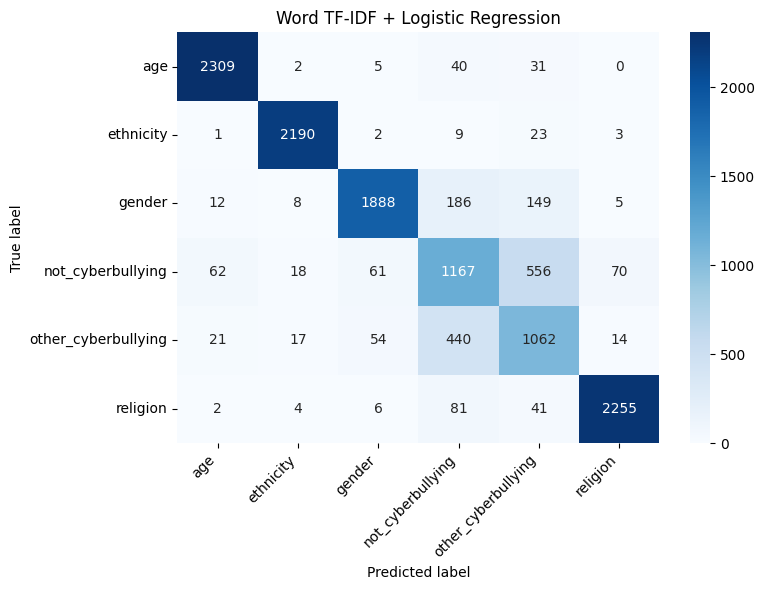

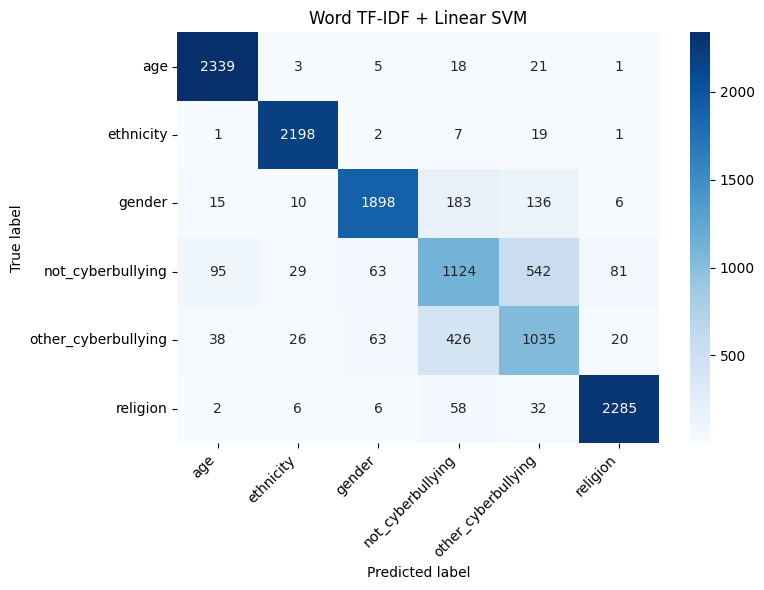

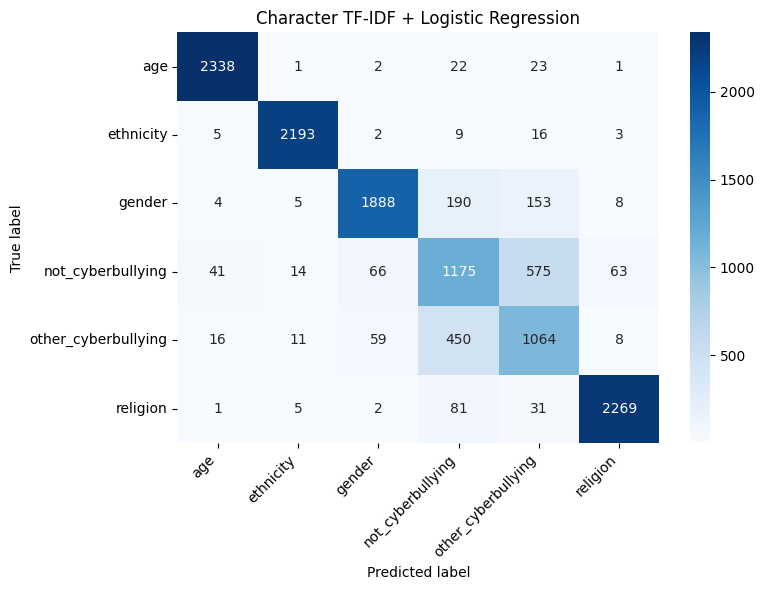

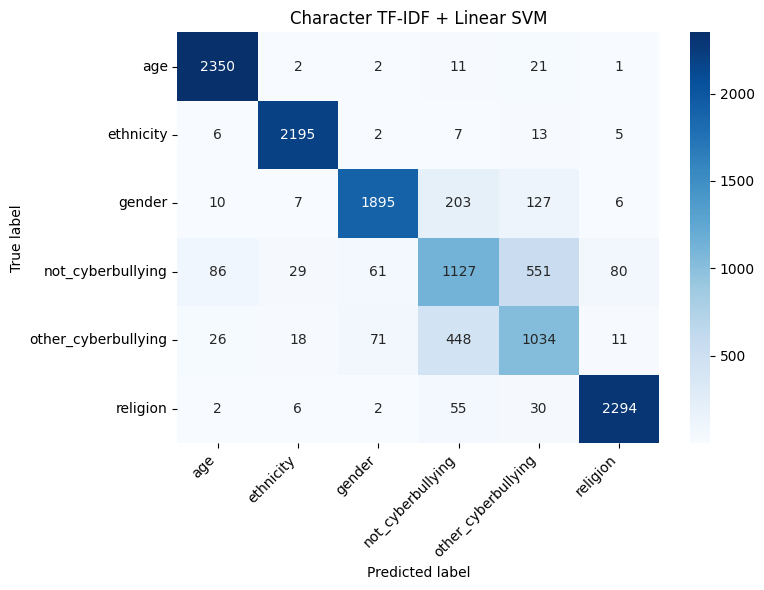

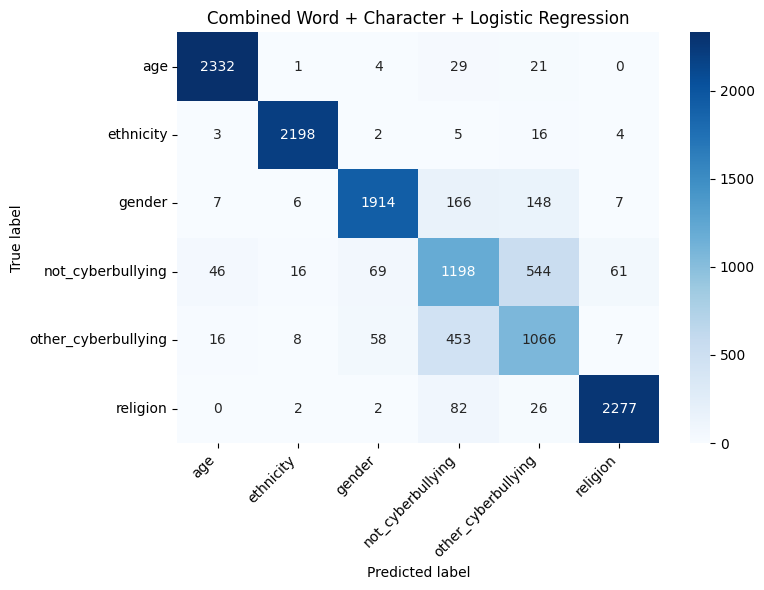

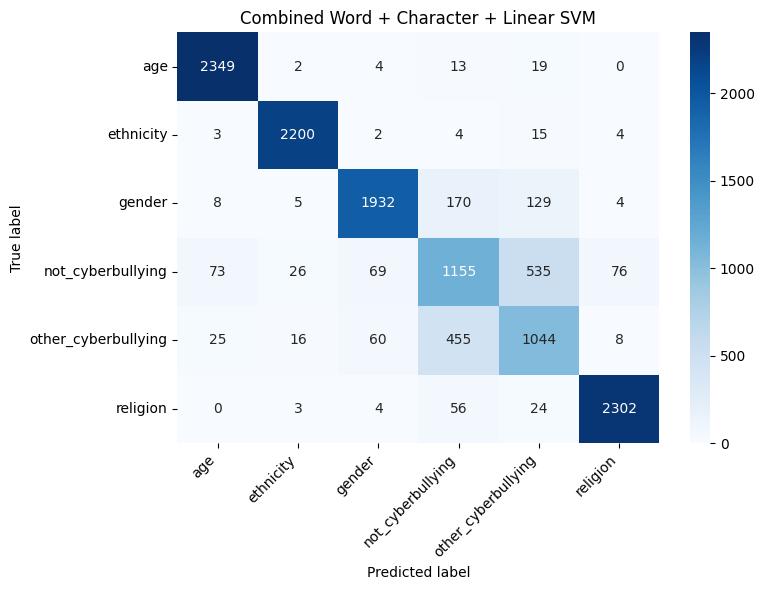


NOT-CYBERBULLYING PERFORMANCE
----------------------------------------------------------------------
Word TF-IDF                  | Logistic Regression    | Precision: 0.6069 | Recall: 0.6034 | F1: 0.6051
Word TF-IDF                  | Linear SVM             | Precision: 0.6189 | Recall: 0.5812 | F1: 0.5995
Character TF-IDF             | Logistic Regression    | Precision: 0.6098 | Recall: 0.6075 | F1: 0.6087
Character TF-IDF             | Linear SVM             | Precision: 0.6089 | Recall: 0.5827 | F1: 0.5955
Combined Word + Character    | Logistic Regression    | Precision: 0.6198 | Recall: 0.6194 | F1: 0.6196
Combined Word + Character    | Linear SVM             | Precision: 0.6233 | Recall: 0.5972 | F1: 0.6100


In [4]:

# ============================================================
# EXPERIMENT: WORD vs CHAR vs COMBINED TF-IDF
# Models: Logistic Regression + Linear SVM
# Features: TF-IDF + Sentiment
# Target: cyberbullying_type
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import hstack, csr_matrix

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

text_col = "lemmatized_tweet"

sentiment_cols = [
    "negative",
    "positive",
    "neutral",
    "compound"
]

target_col = "cyberbullying_type"

# Keep only the required columns and remove missing targets
df_exp = df[
    [text_col] + sentiment_cols + [target_col]
].copy()

df_exp = df_exp.dropna(subset=[target_col])

# Handle missing text and sentiment values
X_text = df_exp[text_col].fillna("").astype(str)

X_sentiment = (
    df_exp[sentiment_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0)
)

y = df_exp[target_col].astype(str)

# Encode target labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", list(label_encoder.classes_))
print("Dataset shape:", df_exp.shape)

# ------------------------------------------------------------
# 2. ONE FIXED, STRATIFIED TRAIN-TEST SPLIT
# ------------------------------------------------------------

(
    X_text_train,
    X_text_test,
    X_sent_train,
    X_sent_test,
    y_train,
    y_test
) = train_test_split(
    X_text,
    X_sentiment,
    y_encoded,
    test_size=0.30,
    random_state=42,
    stratify=y_encoded
)

# Convert sentiment features to sparse matrices
S_train = csr_matrix(X_sent_train.to_numpy(dtype=float))
S_test = csr_matrix(X_sent_test.to_numpy(dtype=float))

print("\nTraining samples:", len(y_train))
print("Testing samples :", len(y_test))

# ------------------------------------------------------------
# 3. DEFINE THREE TEXT REPRESENTATIONS
# max_features=10000 applies separately to each vectorizer
# ------------------------------------------------------------

vectorizer_configs = {
    "Word TF-IDF": {
        "analyzer": "word",
        "ngram_range": (1, 2),
        "max_features": 10000
    },

    "Character TF-IDF": {
        "analyzer": "char",
        "ngram_range": (3, 5),
        "max_features": 10000
    },

    "Combined Word + Character": None
}

# Fit vectorizers using training text only.
# Reuse the same word and character representations
# for both classifiers.

word_vectorizer = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    max_features=10000,
    sublinear_tf=True
)

char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    max_features=10000,
    sublinear_tf=True
)

# Word features
W_train = word_vectorizer.fit_transform(X_text_train)
W_test = word_vectorizer.transform(X_text_test)

# Character features
C_train = char_vectorizer.fit_transform(X_text_train)
C_test = char_vectorizer.transform(X_text_test)

# Combine word + character features
WC_train = hstack([W_train, C_train], format="csr")
WC_test = hstack([W_test, C_test], format="csr")

# Append sentiment features to each representation
representations = {
    "Word TF-IDF": (
        hstack([W_train, S_train], format="csr"),
        hstack([W_test, S_test], format="csr")
    ),

    "Character TF-IDF": (
        hstack([C_train, S_train], format="csr"),
        hstack([C_test, S_test], format="csr")
    ),

    "Combined Word + Character": (
        hstack([WC_train, S_train], format="csr"),
        hstack([WC_test, S_test], format="csr")
    )
}

print("\nFeature matrix dimensions")
print("-" * 55)

for name, (Xtr, Xte) in representations.items():
    print(
        f"{name:28s} | "
        f"Train: {Xtr.shape} | Test: {Xte.shape}"
    )

# ------------------------------------------------------------
# 4. DEFINE CLASSIFIERS
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=10000,
        random_state=42,
        class_weight='balanced'
    ),

    "Linear SVM": LinearSVC(
        C=0.1,
        max_iter=10000,
        random_state=42,
        class_weight='balanced'


    )
}

# ------------------------------------------------------------
# 5. RUN ALL SIX EXPERIMENTS
# ------------------------------------------------------------

results = []
reports = {}
confusion_matrices = {}

for representation_name, (Xtr, Xte) in representations.items():

    for model_name, model_template in models.items():

        print("\n" + "=" * 70)
        print(f"Representation: {representation_name}")
        print(f"Model: {model_name}")
        print("=" * 70)

        # Create a fresh estimator for every experiment
        from sklearn.base import clone
        model = clone(model_template)

        # Train
        model.fit(Xtr, y_train)

        # Predict
        y_pred = model.predict(Xte)

        # Metrics
        accuracy = accuracy_score(y_test, y_pred)
        macro_f1 = f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
        weighted_f1 = f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )

        results.append({
            "Representation": representation_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Macro-F1": macro_f1,
            "Weighted-F1": weighted_f1
        })

        # Store detailed outputs
        key = (representation_name, model_name)

        reports[key] = classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            output_dict=True,
            zero_division=0
        )

        confusion_matrices[key] = confusion_matrix(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_))
        )

        print(f"Accuracy   : {accuracy:.4f}")
        print(f"Macro-F1   : {macro_f1:.4f}")
        print(f"Weighted-F1: {weighted_f1:.4f}")

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        ))

# ------------------------------------------------------------
# 6. COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Macro-F1", "Weighted-F1"],
    ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))

# ------------------------------------------------------------
# 7. CONFUSION MATRIX FOR EACH EXPERIMENT
# ------------------------------------------------------------

for key, cm in confusion_matrices.items():

    representation_name, model_name = key

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_
    )

    plt.title(f"{representation_name} + {model_name}")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. FOCUS CLASS: NOT-CYBERBULLYING
# ------------------------------------------------------------

focus_class = "not_cyberbullying"

if focus_class in label_encoder.classes_:

    print("\nNOT-CYBERBULLYING PERFORMANCE")
    print("-" * 70)

    for key, report in reports.items():

        representation_name, model_name = key
        class_metrics = report[focus_class]

        print(
            f"{representation_name:28s} | "
            f"{model_name:22s} | "
            f"Precision: {class_metrics['precision']:.4f} | "
            f"Recall: {class_metrics['recall']:.4f} | "
            f"F1: {class_metrics['f1-score']:.4f}"
        )

else:
    print(
        f"Focus class '{focus_class}' not found. "
        "Check label_encoder.classes_."
    )
